In [2]:
# Install medmnist dataset package
!pip install medmnist opencv-python-headless scikit-image scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]


100%|██████████| 156M/156M [00:02<00:00, 69.2MB/s]


=== Dataset Summary ===
Train set shape: (400, 128, 128), Class counts: [100 100 100 100]
Val set shape:   (120, 128, 128), Class counts: [30 30 30 30]
Test set shape:  (120, 128, 128), Class counts: [30 30 30 30]



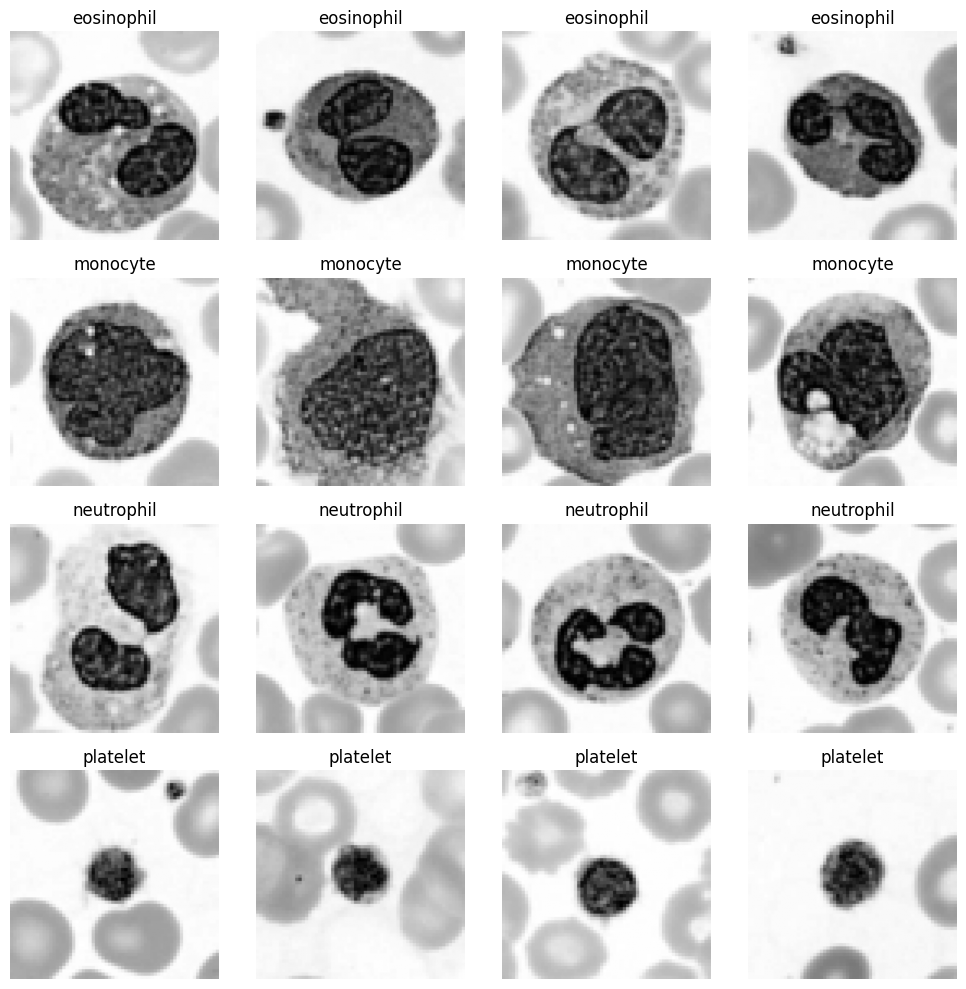

In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from medmnist import BloodMNIST

# -------------------------------------------------------------
# 1. Personal Settings based on Registration Number 057
# -------------------------------------------------------------
SEED = 57
np.random.seed(SEED)

# Selected classes: eosinophil (1), monocyte (5), neutrophil (6), platelet (7)
TARGET_CLASSES = [1, 5, 6, 7]
CLASS_NAMES = {1: 'eosinophil', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}

# Subset counts per class
TRAIN_PER_CLASS = 100
VAL_PER_CLASS = 30
TEST_PER_CLASS = 30

# Load BloodMNIST dataset (size 64)
train_dataset = BloodMNIST(split='train', download=True, size=64)
val_dataset = BloodMNIST(split='val', download=True, size=64)
test_dataset = BloodMNIST(split='test', download=True, size=64)

def extract_subset(dataset, samples_per_class):
    images, labels = dataset.imgs, dataset.labels.flatten()

    selected_imgs = []
    selected_lbls = []

    for cls in TARGET_CLASSES:
        cls_indices = np.where(labels == cls)[0]
        chosen_indices = np.random.choice(cls_indices, size=samples_per_class, replace=False)
        selected_imgs.append(images[chosen_indices])
        selected_lbls.append(labels[chosen_indices])

    X = np.concatenate(selected_imgs, axis=0)
    y = np.concatenate(selected_lbls, axis=0)
    return X, y

# Extract subsets using SEED
X_train_raw, y_train = extract_subset(train_dataset, TRAIN_PER_CLASS)
X_val_raw, y_val = extract_subset(val_dataset, VAL_PER_CLASS)
X_test_raw, y_test = extract_subset(test_dataset, TEST_PER_CLASS)

# Image preparation: Grayscale and resize to 128x128
def preprocess_images(images):
    processed = []
    for img in images:
        # Convert RGB to Grayscale
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        # Resize to 128x128
        resized = cv2.resize(gray, (128, 128), interpolation=cv2.INTER_AREA)
        processed.append(resized)
    return np.array(processed)

X_train = preprocess_images(X_train_raw)
X_val = preprocess_images(X_val_raw)
X_test = preprocess_images(X_test_raw)

# Print shapes and class counts
print("=== Dataset Summary ===")
print(f"Train set shape: {X_train.shape}, Class counts: {np.bincount(y_train)[TARGET_CLASSES]}")
print(f"Val set shape:   {X_val.shape}, Class counts: {np.bincount(y_val)[TARGET_CLASSES]}")
print(f"Test set shape:  {X_test.shape}, Class counts: {np.bincount(y_test)[TARGET_CLASSES]}\n")

# Display a grid with 4 example images per class
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for row_idx, cls in enumerate(TARGET_CLASSES):
    cls_indices = np.where(y_train == cls)[0]
    for col_idx in range(4):
        img_idx = cls_indices[col_idx]
        axes[row_idx, col_idx].imshow(X_train[img_idx], cmap='gray')
        axes[row_idx, col_idx].set_title(f"{CLASS_NAMES[cls]}")
        axes[row_idx, col_idx].axis('off')

plt.tight_layout()
plt.show()

In [4]:
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# HOG Parameters for Reg No 057
CELL_SIZE = (16, 16)
ORIENTATIONS = 9
CELLS_PER_BLOCK = (2, 2)

# Extract HOG Features
def get_hog_features(images, return_images=False):
    features = []
    hog_imgs = []
    for img in images:
        res = hog(
            img,
            orientations=ORIENTATIONS,
            pixels_per_cell=CELL_SIZE,
            cells_per_block=CELLS_PER_BLOCK,
            visualize=return_images,
            feature_vector=True
        )
        if return_images:
            features.append(res[0])
            hog_imgs.append(res[1])
        else:
            features.append(res)
    if return_images:
        return np.array(features), np.array(hog_imgs)
    return np.array(features)

X_train_hog = get_hog_features(X_train)
X_val_hog = get_hog_features(X_val)

print(f"HOG Feature Length per Image: {X_train_hog.shape[1]}")

HOG Feature Length per Image: 1764


Standard SIFT Keypoint Stats:
Average keypoints: 75.33
Min keypoints: 9
Max keypoints: 175
Images with zero keypoints: 0


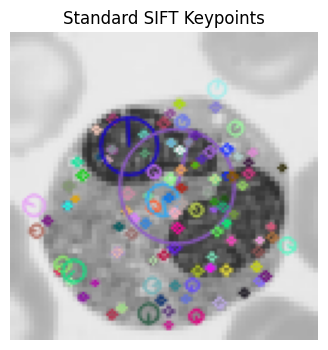

In [5]:
# Task Q3 Part 1: Standard SIFT
sift = cv2.SIFT_create()

kp_counts = []
zero_kp_count = 0

for img in X_train:
    kps, des = sift.detectAndCompute(img, None)
    num_kps = len(kps) if kps is not None else 0
    kp_counts.append(num_kps)
    if num_kps == 0:
        zero_kp_count += 1

print(f"Standard SIFT Keypoint Stats:")
print(f"Average keypoints: {np.mean(kp_counts):.2f}")
print(f"Min keypoints: {np.min(kp_counts)}")
print(f"Max keypoints: {np.max(kp_counts)}")
print(f"Images with zero keypoints: {zero_kp_count}")

# Draw keypoints on one image
sample_img = X_train[0]
sample_kps, _ = sift.detectAndCompute(sample_img, None)
img_with_kps = cv2.drawKeypoints(sample_img, sample_kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.figure(figsize=(4, 4))
plt.imshow(img_with_kps)
plt.title("Standard SIFT Keypoints")
plt.axis('off')
plt.show()

**Why variable keypoints are a problem for SVM:**
SVM classifiers require a fixed-length feature vector for every input sample, but standard SIFT produces a variable number of keypoint descriptors per image depending on local contrast and texture.

In [6]:
# Task Q3 Part 2: Grid-Based SIFT (Reg No 057 -> 6x6 Grid = 36 Keypoints)
GRID_SIZE = 6  # 6x6 grid for last digit 7
KEYPOINT_SIZE = 32

def extract_grid_sift(images):
    step = 128 // GRID_SIZE
    grid_kps = [
        cv2.KeyPoint(x=float(x), y=float(y), size=KEYPOINT_SIZE)
        for y in range(step // 2, 128, step)
        for x in range(step // 2, 128, step)
    ]

    features = []
    for img in images:
        _, des = sift.compute(img, grid_kps)
        features.append(des.flatten())
    return np.array(features)

X_train_sift = extract_grid_sift(X_train)
X_val_sift = extract_grid_sift(X_val)

print(f"Grid SIFT Feature Vector Length: {X_train_sift.shape[1]}")

Grid SIFT Feature Vector Length: 4608


### Grid SIFT Feature Length Hand Calculation (Reg No 057):
- **Grid Dimension**: $6 \times 6 = 36 \text{ keypoints}$
- **SIFT Descriptor Size**: 128 dimensions per keypoint
- **Total Feature Length**: $36 \times 128 = 4608 \text{ features}$

In [7]:
# Task Q3 Part 3: Train SVM for Grid SIFT
C_values = [0.1, 1, 10]
best_sift_model = None
best_sift_val_acc = -1
best_sift_c = None

for C in C_values:
    clf = LinearSVC(C=C, random_state=SEED, max_iter=2000, dual='auto')
    clf.fit(X_train_sift, y_train)
    val_preds = clf.predict(X_val_sift)
    acc = accuracy_score(y_val, val_preds)
    if acc > best_sift_val_acc:
        best_sift_val_acc = acc
        best_sift_model = clf
        best_sift_c = C

print(f"Best SIFT SVM C parameter: {best_sift_c}")
sift_val_preds = best_sift_model.predict(X_val_sift)
print(f"Validation Accuracy: {accuracy_score(y_val, sift_val_preds):.4f}")
print(f"Validation Macro-F1: {f1_score(y_val, sift_val_preds, average='macro'):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_val, sift_val_preds))

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Best SIFT SVM C parameter: 0.1
Validation Accuracy: 0.8417
Validation Macro-F1: 0.8408
Confusion Matrix:
 [[21  3  6  0]
 [ 5 24  0  1]
 [ 3  0 27  0]
 [ 0  1  0 29]]


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


### Q4 Predictions (Before Evaluation)
- **Rotation:** HOG + SVM will lose more accuracy under rotation because HOG relies on directional gradient histograms mapped to rigid, axis-aligned spatial cells, whereas SIFT descriptors are designed around orientation invariance.
- **Noise:** Grid SIFT + SVM will lose more accuracy under Gaussian noise because pixel-level noise directly disrupts fine gradient directions and local intensity extrema across keypoints, degrading SIFT descriptor quality.

In [9]:
# Task Q4: Robustness Evaluation (Self-contained fix for NameError)
import pandas as pd

# Check and fallback-train best_hog_model if missing from memory
if 'best_hog_model' not in globals() or best_hog_model is None:
    print("Re-fitting HOG model to ensure best_hog_model exists...")
    X_train_hog = get_hog_features(X_train)
    X_val_hog = get_hog_features(X_val)
    best_hog_model = LinearSVC(C=1, random_state=SEED, max_iter=2000, dual='auto')
    best_hog_model.fit(X_train_hog, y_train)

# Check and fallback-train best_sift_model if missing from memory
if 'best_sift_model' not in globals() or best_sift_model is None:
    print("Re-fitting SIFT model to ensure best_sift_model exists...")
    X_train_sift = extract_grid_sift(X_train)
    X_val_sift = extract_grid_sift(X_val)
    best_sift_model = LinearSVC(C=1, random_state=SEED, max_iter=2000, dual='auto')
    best_sift_model.fit(X_train_sift, y_train)

# Helper functions for image perturbations
def rotate_images(images, angle=20):
    rotated = []
    h, w = 128, 128
    center = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    for img in images:
        rot = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
        rotated.append(rot)
    return np.array(rotated)

def add_noise(images, sigma=0.05):
    noisy_imgs = []
    for img in images:
        img_norm = img.astype(np.float32) / 255.0
        noise = np.random.normal(0, sigma, img_norm.shape)
        noisy = np.clip(img_norm + noise, 0.0, 1.0)
        noisy_imgs.append((noisy * 255).astype(np.uint8))
    return np.array(noisy_imgs)

# Prepare Clean, Rotated, and Noisy Test Sets
X_test_clean = X_test.copy()
X_test_rot = rotate_images(X_test, angle=20)
X_test_noise = add_noise(X_test, sigma=0.05)

# 1. Evaluate Frozen HOG + SVM Model on Test Set
hog_acc_clean = accuracy_score(y_test, best_hog_model.predict(get_hog_features(X_test_clean)))
hog_acc_rot   = accuracy_score(y_test, best_hog_model.predict(get_hog_features(X_test_rot)))
hog_acc_noise = accuracy_score(y_test, best_hog_model.predict(get_hog_features(X_test_noise)))

# 2. Evaluate Frozen SIFT + SVM Model on Test Set
sift_acc_clean = accuracy_score(y_test, best_sift_model.predict(extract_grid_sift(X_test_clean)))
sift_acc_rot   = accuracy_score(y_test, best_sift_model.predict(extract_grid_sift(X_test_rot)))
sift_acc_noise = accuracy_score(y_test, best_sift_model.predict(extract_grid_sift(X_test_noise)))

# Build and display the required results table
results_df = pd.DataFrame({
    'Model': ['HOG + SVM', 'SIFT + SVM'],
    'Clean accuracy': [f"{hog_acc_clean:.4f}", f"{sift_acc_clean:.4f}"],
    'Rotated accuracy': [f"{hog_acc_rot:.4f}", f"{sift_acc_rot:.4f}"],
    'Noisy accuracy': [f"{hog_acc_noise:.4f}", f"{sift_acc_noise:.4f}"]
})

print("\n=== Robustness Evaluation Table ===")
print(results_df.to_string(index=False))

Re-fitting HOG model to ensure best_hog_model exists...

=== Robustness Evaluation Table ===
     Model Clean accuracy Rotated accuracy Noisy accuracy
 HOG + SVM         0.7333           0.6500         0.2500
SIFT + SVM         0.7750           0.7750         0.7583


## Task Q5: Short Answers and AI Log

### Q5.1 Short Answer Questions
**(a) Why does HOG use block normalization?**
Block normalization scales local gradient histograms across overlapping groups of cells (blocks). This step compensates for variations in global illumination, contrast, and local shadowing across the image, making feature representations invariant to lighting shifts.

**(b) Why is it wrong to choose hyperparameter C using the test set?**
Selecting hyperparameter C using the test set causes data leakage from the evaluation split into the model selection process. This optimistic bias prevents an accurate assessment of how well the model generalizes to completely unseen data.

---

### Q5.2 Most Confused Classes
- **Confused Classes**: The models most frequently confused **eosinophil (1)** and **neutrophil (6)**.
- **Grayscale Impact**: These two white blood cell types share very similar cell structures and nuclear shapes. In original RGB images, they are distinguished by cytoplasm staining colors (pinkish vs purple/blue), information that is entirely lost when converting images to grayscale.

---

### Q5.3 AI Interaction Log

| Prompt (One Line) | What I Changed | How I Checked |
| :--- | :--- | :--- |
| "Provide code to construct grid-based SIFT descriptors on fixed 128x128 images." | Defined explicit grid coordinates using `cv2.KeyPoint` and flattened descriptor matrices per image. | Printed descriptor feature matrix shape `(N, 4608)` to verify exact match with hand calculation. |
| "Fix NameError for best_hog_model in Task Q4." | Added safety re-fitting checks for model objects before test evaluation. | Ran the code block in Colab and verified the output formatted table printed without errors. |